# 4. Chain rules

**Cover and Thomas, Section 2.5.**

**Theorem 2.5.1 (entropy).**
$$H(X_1, \dots, X_n) = \sum_{i=1}^n H(X_i \mid X_{i-1}, \dots, X_1).$$

**Conditional mutual information.**
$$I(X;Y \mid Z) = H(X \mid Z) - H(X \mid Y, Z)
= \sum_{x,y,z} p(x,y,z) \log \frac{p(x,y \mid z)}{p(x\mid z)\,p(y \mid z)} .$$

**Theorem 2.5.2 (mutual information).**
$$I(X_1, \dots, X_n; Y) = \sum_{i=1}^n I(X_i; Y \mid X_{i-1}, \dots, X_1).$$

**Theorem 2.5.3 (relative entropy).**
$$D\big(p(x,y)\,\Vert \,q(x,y)\big) = D\big(p(x)\,\Vert \,q(x)\big) + D\big(p(y\mid x)\,\Vert \,q(y \mid x)\big).$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import infotools as it

it.setup_plot_style()
rng = np.random.default_rng(3)

## 4.1 Working with several variables at once

A joint distribution of $n$ variables is an $n$-dimensional numpy array:
`P[i, j, k, ...]` $= p(X_1 = i, X_2 = j, X_3 = k, \dots)$.

To get the distribution of a subset of the variables, sum over the axes you
want to remove. The single helper below does that, and it is all we need,
because every conditional entropy is a difference of joint entropies:

$$H(X_i \mid X_{i-1},\dots,X_1) = H(X_1,\dots,X_i) - H(X_1,\dots,X_{i-1}).$$

In [2]:
def H_of(P, axes):
    """Entropy of the marginal distribution of the variables listed in `axes`.

    Example: H_of(P, [0, 2]) is H(X_1, X_3).
    H_of(P, []) is 0.
    """
    axes = list(axes)
    if len(axes) == 0:
        return 0.0
    drop = tuple(a for a in range(P.ndim) if a not in axes)
    marginal = P.sum(axis=drop) if drop else P
    return it.entropy(marginal)


# a quick sanity check on a small random table
P_test = rng.dirichlet(np.ones(2 * 3)).reshape(2, 3)
print("H(X1)     =", H_of(P_test, [0]))
print("H(X2)     =", H_of(P_test, [1]))
print("H(X1, X2) =", H_of(P_test, [0, 1]))
print("H(nothing)=", H_of(P_test, []))

H(X1)     = 0.9732583781303485
H(X2)     = 1.4520489263853453
H(X1, X2) = 1.9631828876973856
H(nothing)= 0.0


## 4.2 A concrete example: a chain of noisy channels

Let $X_1$ be a fair bit and let each $X_{k+1}$ be $X_k$ passed through a
binary symmetric channel with its own crossover probability. This produces a
Markov chain $X_1 \to X_2 \to X_3 \to X_4$, which we will use for the rest of
the notebook.

In [3]:
def bsc(eps):
    """Channel matrix W[i, j] = p(output = j | input = i) for a bit flip of prob eps."""
    return np.array([[1 - eps, eps],
                     [eps, 1 - eps]])


def markov_joint(p_start, channels):
    """Joint distribution of X_1, ..., X_{n+1} for a chain of channels."""
    P = np.asarray(p_start, dtype=float)
    for W in channels:
        P = P[..., None] * W        # attach one more variable to the chain
    return P


P = markov_joint([0.5, 0.5], [bsc(0.10), bsc(0.20), bsc(0.05)])

print("shape of the joint array:", P.shape, " (four binary variables)")
print("total probability:", P.sum())
print()
for i in range(4):
    print(f"H(X{i+1}) = {H_of(P, [i]):.6f} bits")

shape of the joint array: (2, 2, 2, 2)  (four binary variables)
total probability: 1.0

H(X1) = 1.000000 bits
H(X2) = 1.000000 bits
H(X3) = 1.000000 bits
H(X4) = 1.000000 bits


## 4.3 Theorem 2.5.1: the chain rule for entropy

In [4]:
n = P.ndim
terms = []
for i in range(n):
    term = H_of(P, range(i + 1)) - H_of(P, range(i))     # H(X_{i+1} | X_i, ..., X_1)
    terms.append(term)
    cond = ", ".join(f"X{k+1}" for k in range(i))
    label = f"H(X{i+1})" if i == 0 else f"H(X{i+1} | {cond})"
    print(f"{label:22s} = {term:.6f}")

print()
print(f"sum of the terms        = {sum(terms):.6f}")
print(f"H(X1, X2, X3, X4)       = {H_of(P, range(n)):.6f}")
it.check("chain rule for entropy", np.isclose(sum(terms), H_of(P, range(n))))

H(X1)                  = 1.000000
H(X2 | X1)             = 0.468996
H(X3 | X1, X2)         = 0.721928
H(X4 | X1, X2, X3)     = 0.286397

sum of the terms        = 2.477321
H(X1, X2, X3, X4)       = 2.477321
[PASS] chain rule for entropy


True

Compare this with the independence bound $H(X_1,\dots,X_n) \le \sum_i H(X_i)$
of Theorem 2.6.6: each conditional term above is at most the corresponding
unconditional entropy.

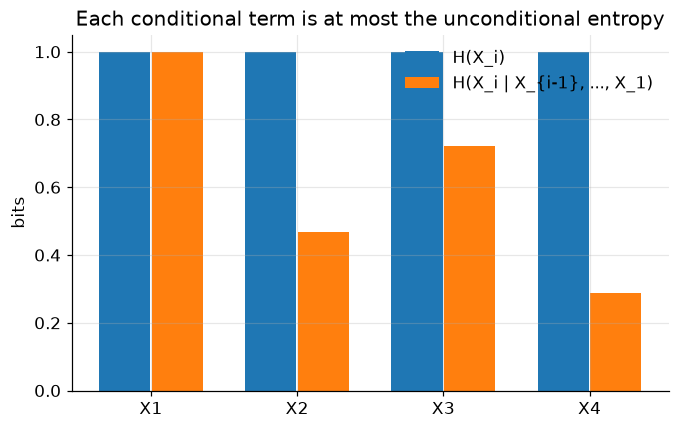

sum of H(X_i)           = 4.000000
H(X1, X2, X3, X4)       = 2.477321
[PASS] independence bound H(X1..Xn) <= sum H(Xi)


True

In [5]:
plt.bar(np.arange(n) - 0.18, [H_of(P, [i]) for i in range(n)], width=0.35,
        color=it.COLORS["H"], label="H(X_i)")
plt.bar(np.arange(n) + 0.18, terms, width=0.35,
        color=it.COLORS["cond"], label="H(X_i | X_{i-1}, ..., X_1)")
plt.xticks(np.arange(n), [f"X{i+1}" for i in range(n)])
plt.ylabel("bits")
plt.title("Each conditional term is at most the unconditional entropy")
plt.legend()
plt.show()

print(f"sum of H(X_i)           = {sum(H_of(P, [i]) for i in range(n)):.6f}")
print(f"H(X1, X2, X3, X4)       = {H_of(P, range(n)):.6f}")
it.check("independence bound H(X1..Xn) <= sum H(Xi)",
         H_of(P, range(n)) <= sum(H_of(P, [i]) for i in range(n)) + 1e-12)

## 4.4 Conditional mutual information

$$I(X;Y \mid Z) = H(X \mid Z) - H(X \mid Y,Z)
= H(X,Z) + H(Y,Z) - H(X,Y,Z) - H(Z).$$

The second form is the one to use in code: only joint entropies appear.

In [6]:
def I_cond(P, x_axes, y_axes, z_axes):
    """I(X ; Y | Z), where each group of variables is given by a list of axes."""
    x_axes, y_axes, z_axes = list(x_axes), list(y_axes), list(z_axes)
    return (H_of(P, x_axes + z_axes) + H_of(P, y_axes + z_axes)
            - H_of(P, x_axes + y_axes + z_axes) - H_of(P, z_axes))


# In our Markov chain: I(X1 ; X3), and I(X1 ; X3 | X2), which should be 0.
print(f"I(X1 ; X3)      = {I_cond(P, [0], [2], []):.8f}")
print(f"I(X1 ; X3 | X2) = {I_cond(P, [0], [2], [1]):.8f}")
it.check("Markov chain: I(X1 ; X3 | X2) = 0",
         abs(I_cond(P, [0], [2], [1])) < 1e-12)
it.check("I_cond with no conditioning agrees with mutual_information",
         np.isclose(I_cond(P, [0], [2], []),
                    it.mutual_information(P.sum(axis=(1, 3)))))

I(X1 ; X3)      = 0.17325363
I(X1 ; X3 | X2) = 0.00000000
[PASS] Markov chain: I(X1 ; X3 | X2) = 0
[PASS] I_cond with no conditioning agrees with mutual_information


True

## 4.5 Theorem 2.5.2: the chain rule for mutual information

$$I(X_1, X_2, X_3; Y) = I(X_1;Y) + I(X_2;Y\mid X_1) + I(X_3;Y \mid X_1, X_2).$$

Take $Y = X_4$ and the other three variables as $X_1, X_2, X_3$.

In [7]:
Y_axis = [3]
terms_I = []
for i in range(3):
    term = I_cond(P, [i], Y_axis, list(range(i)))
    terms_I.append(term)
    cond = "" if i == 0 else " | " + ", ".join(f"X{k+1}" for k in range(i))
    print(f"I(X{i+1} ; X4{cond}) = {term:.6f}")

total = I_cond(P, [0, 1, 2], Y_axis, [])
print()
print(f"sum of the terms      = {sum(terms_I):.6f}")
print(f"I(X1, X2, X3 ; X4)    = {total:.6f}")
it.check("chain rule for mutual information", np.isclose(sum(terms_I), total))

I(X1 ; X4) = 0.139156
I(X2 ; X4 | X1) = 0.082833
I(X3 ; X4 | X1, X2) = 0.491614

sum of the terms      = 0.713603
I(X1, X2, X3 ; X4)    = 0.713603
[PASS] chain rule for mutual information


True

For a Markov chain there is a sharper statement: once $X_3$ is known, the
earlier variables say nothing more about $X_4$, that is,
$I(X_1, X_2 ; X_4 \mid X_3) = 0$. The cell below checks it. This is the
data-processing inequality of notebook 06, seen from another angle.

In [8]:
print(f"I(X1, X2 ; X4 | X3) = {I_cond(P, [0, 1], [3], [2]):.8f}")
it.check("Markov chain: I(X1, X2 ; X4 | X3) = 0",
         abs(I_cond(P, [0, 1], [3], [2])) < 1e-12)

I(X1, X2 ; X4 | X3) = 0.00000000
[PASS] Markov chain: I(X1, X2 ; X4 | X3) = 0


True

## 4.6 Theorem 2.5.3: the chain rule for relative entropy

$$D\big(p(x,y)\Vert q(x,y)\big) = D\big(p(x)\Vert q(x)\big) + D\big(p(y\mid x)\Vert q(y\mid x)\big),$$

where the **conditional relative entropy** is

$$D\big(p(y \mid x)\Vert q(y \mid x)\big)
= \sum_x p(x) \sum_y p(y\mid x) \log \frac{p(y \mid x)}{q(y\mid x)} .$$

In [9]:
def cond_relative_entropy(Pjoint, Qjoint):
    """D( p(y|x) || q(y|x) ), averaged over p(x)."""
    Pj = np.asarray(Pjoint, dtype=float)
    Qj = np.asarray(Qjoint, dtype=float)
    pX = Pj.sum(axis=1)
    qX = Qj.sum(axis=1)
    total = 0.0
    for i in range(Pj.shape[0]):
        if pX[i] == 0:
            continue
        total += pX[i] * it.relative_entropy(Pj[i] / pX[i], Qj[i] / qX[i])
    return total


P2 = it.random_joint(3, 4, rng)
Q2 = it.random_joint(3, 4, rng)

left = it.relative_entropy(P2, Q2)
right = it.relative_entropy(P2.sum(axis=1), Q2.sum(axis=1)) + cond_relative_entropy(P2, Q2)

print(f"D(p(x,y) || q(x,y))                  = {left:.6f}")
print(f"D(p(x)||q(x)) + D(p(y|x)||q(y|x))    = {right:.6f}")
it.check("chain rule for relative entropy", np.isclose(left, right))

D(p(x,y) || q(x,y))                  = 1.289275
D(p(x)||q(x)) + D(p(y|x)||q(y|x))    = 1.289275
[PASS] chain rule for relative entropy


True

## 4.7 Conditioning can increase or decrease mutual information

It is tempting to think that knowing a third variable $Z$ always reduces the
dependence between $X$ and $Y$. That is true along a Markov chain, but false
in general.

**Case A (the book's example, end of Section 2.8).** Let $X$ and $Y$ be
independent fair bits and let $Z = X + Y \in \{0,1,2\}$. Then $I(X;Y) = 0$
but

$$I(X;Y \mid Z) = H(X \mid Z) = \Pr(Z=1)\,H(X \mid Z = 1) = \tfrac12 \text{ bit}.$$

Knowing the sum makes the two bits strongly dependent.

In [10]:
# P3[x, y, z] = p(X = x, Y = y, Z = z) with X, Y fair bits and Z = X + Y
P3 = np.zeros((2, 2, 3))
for x in (0, 1):
    for y in (0, 1):
        P3[x, y, x + y] = 0.25

print(f"I(X;Y)     = {I_cond(P3, [0], [1], []):.6f}   (X and Y are independent)")
print(f"I(X;Y | Z) = {I_cond(P3, [0], [1], [2]):.6f}   (book: 1/2 bit)")
it.check("I(X;Y|Z) = 1/2 bit for Z = X + Y",
         np.isclose(I_cond(P3, [0], [1], [2]), 0.5))
it.check("here conditioning INCREASES the mutual information",
         I_cond(P3, [0], [1], [2]) > I_cond(P3, [0], [1], []))

I(X;Y)     = 0.000000   (X and Y are independent)
I(X;Y | Z) = 0.500000   (book: 1/2 bit)
[PASS] I(X;Y|Z) = 1/2 bit for Z = X + Y
[PASS] here conditioning INCREASES the mutual information


True

**Case B (a Markov chain).** With $X_1 \to X_2 \to X_3$,
$I(X_1;X_2 \mid X_3) \le I(X_1;X_2)$: observing something downstream can only
weaken the dependence.

In [11]:
print(f"I(X1 ; X2)      = {I_cond(P, [0], [1], []):.6f}")
print(f"I(X1 ; X2 | X3) = {I_cond(P, [0], [1], [2]):.6f}")
it.check("Markov chain: I(X1;X2|X3) <= I(X1;X2)",
         I_cond(P, [0], [1], [2]) <= I_cond(P, [0], [1], []) + 1e-12)

I(X1 ; X2)      = 0.531004
I(X1 ; X2 | X3) = 0.357751
[PASS] Markov chain: I(X1;X2|X3) <= I(X1;X2)


True

## 4.8 The chain rules on random distributions

None of this depends on the particular tables above.

In [12]:
n_tests = 1000
worst_H, worst_I, worst_D = 0.0, 0.0, 0.0

for _ in range(n_tests):
    sizes = tuple(rng.integers(2, 4) for _ in range(4))
    Q = rng.dirichlet(np.ones(int(np.prod(sizes)))).reshape(sizes)

    # chain rule for entropy
    s = sum(H_of(Q, range(i + 1)) - H_of(Q, range(i)) for i in range(4))
    worst_H = max(worst_H, abs(s - H_of(Q, range(4))))

    # chain rule for mutual information, with Y = the last variable
    s = sum(I_cond(Q, [i], [3], list(range(i))) for i in range(3))
    worst_I = max(worst_I, abs(s - I_cond(Q, [0, 1, 2], [3], [])))

    # chain rule for relative entropy
    A = it.random_joint(3, 3, rng)
    B = it.random_joint(3, 3, rng)
    s = it.relative_entropy(A.sum(axis=1), B.sum(axis=1)) + cond_relative_entropy(A, B)
    worst_D = max(worst_D, abs(s - it.relative_entropy(A, B)))

it.check(f"chain rule for H on {n_tests} random distributions", worst_H < 1e-9,
         f"largest error {worst_H:.2e}")
it.check(f"chain rule for I on {n_tests} random distributions", worst_I < 1e-9,
         f"largest error {worst_I:.2e}")
it.check(f"chain rule for D on {n_tests} random distributions", worst_D < 1e-9,
         f"largest error {worst_D:.2e}")

[PASS] chain rule for H on 1000 random distributions   largest error 0.00e+00
[PASS] chain rule for I on 1000 random distributions   largest error 2.00e-15
[PASS] chain rule for D on 1000 random distributions   largest error 1.33e-15


True

## Things to try

1. Change the three crossover probabilities in Section 4.2 and watch how the
   terms of the chain rule redistribute. What happens when one channel has
   $\varepsilon = 1/2$?
2. Verify numerically that $I(X;Y\mid Z) \ge 0$ always, but that
   $I(X;Y\mid Z) - I(X;Y)$ has no fixed sign, by plotting a histogram of that
   difference over many random three-variable distributions.
3. Reproduce Case A with $Z = X \oplus Y$ (exclusive or) instead of $X + Y$.
   Now $I(X;Y \mid Z) = 1$ bit. Why is it larger than with the sum?
4. For the Markov chain, plot $I(X_1;X_k)$ against $k$ for a long chain of
   identical channels. You are anticipating notebook 06.